# 🏦 Loan Approval Prediction System

### A Beginner-Friendly Machine Learning Project

**Objective:** Predict whether a loan application will be **Approved** or **Rejected** based on applicant details, income, assets, and credit history (CIBIL score).

This notebook walks through the complete data science workflow:
1. Data Understanding
2. Exploratory Data Analysis (EDA)
3. Data Preprocessing
4. Model Building (Logistic Regression, Decision Tree, Random Forest)
5. Model Evaluation
6. Model Saving (for deployment in the Streamlit app)

---


## 📦 Step 0: Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report,
                              roc_curve, roc_auc_score)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("✅ Libraries imported successfully!")


✅ Libraries imported successfully!


---
## 📊 Step 1: Data Understanding

In this step we load the dataset and get a first look at its structure, size, and content.


In [2]:
# Load the dataset
df = pd.read_csv("loan_approval_dataset.csv")

# Clean column names (the raw file has leading spaces in column names)
df.columns = df.columns.str.strip()

# Clean string values (categorical columns also have leading spaces)
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("✅ Dataset loaded successfully!")


✅ Dataset loaded successfully!


### Dataset Shape
Let's see how many rows (loan applications) and columns (features) we have.

In [3]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")


Rows: 4269
Columns: 13


### First 5 Rows
A quick look at the top of the dataset.

In [4]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


### Last 5 Rows
A quick look at the bottom of the dataset.

In [5]:
df.tail()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
4264,4265,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,4266,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,4267,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,4268,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved
4268,4269,1,Graduate,No,9200000,29700000,10,607,17800000,11800000,35700000,12000000,Approved


### Dataset Information
`df.info()` shows column data types and non-null counts — useful for spotting missing data or wrong data types.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   loan_id                   4269 non-null   int64
 1   no_of_dependents          4269 non-null   int64
 2   education                 4269 non-null   str  
 3   self_employed             4269 non-null   str  
 4   income_annum              4269 non-null   int64
 5   loan_amount               4269 non-null   int64
 6   loan_term                 4269 non-null   int64
 7   cibil_score               4269 non-null   int64
 8   residential_assets_value  4269 non-null   int64
 9   commercial_assets_value   4269 non-null   int64
 10  luxury_assets_value       4269 non-null   int64
 11  bank_asset_value          4269 non-null   int64
 12  loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 433.7 KB


### Statistical Summary
`df.describe()` gives count, mean, standard deviation, min/max, and quartiles for every numeric column.

In [7]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


### Missing Values Check
We check every column for missing (null) values.

In [8]:
missing = df.isnull().sum()
print("Missing values per column:\n")
print(missing)


Missing values per column:

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64


### Duplicate Values Check
We check whether any rows are exact duplicates of one another.

In [9]:
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")


Number of duplicate rows: 0


### Unique Values of Categorical Columns
Understanding the categories present in `education`, `self_employed`, and the target column `loan_status`.


In [10]:
categorical_cols = ["education", "self_employed", "loan_status"]
for col in categorical_cols:
    print(f"{col}: {df[col].unique()}")


education: <StringArray>
['Graduate', 'Not Graduate']
Length: 2, dtype: str
self_employed: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
loan_status: <StringArray>
['Approved', 'Rejected']
Length: 2, dtype: str


### 🔎 Observations
- The dataset has **4,269 loan applications** with **13 columns**.
- There are **no missing values** and **no duplicate rows** — the dataset is already clean.
- We have 3 categorical columns: `education`, `self_employed`, and the target `loan_status`.
- `loan_id` is just an identifier and carries no predictive value, so it will be dropped later.


---
## 📈 Step 2: Exploratory Data Analysis (EDA)

Now we visualize the data to understand patterns, distributions, and relationships between features.


### Missing Value Visualization
A heatmap makes it easy to visually confirm there are no missing values.

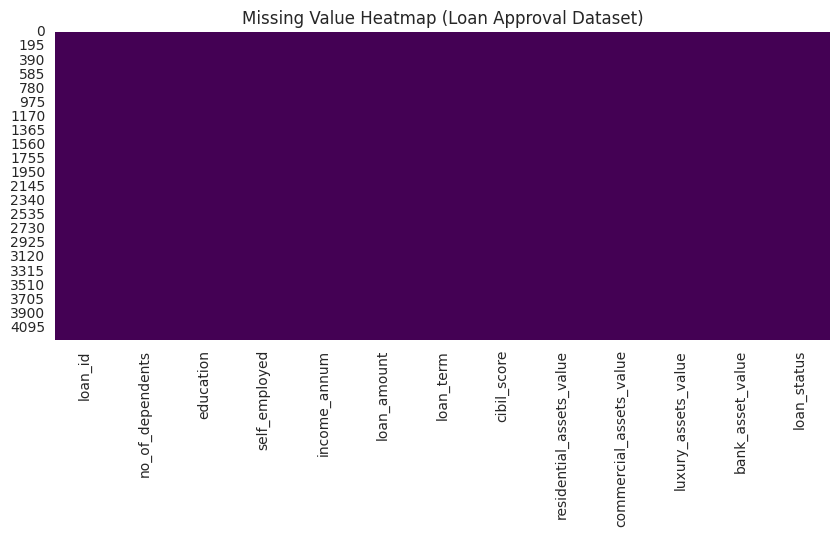

In [11]:
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Value Heatmap (Loan Approval Dataset)")
plt.show()


### Class Distribution (Target Variable)
We check how many loans were Approved vs Rejected. This tells us if the dataset is balanced.


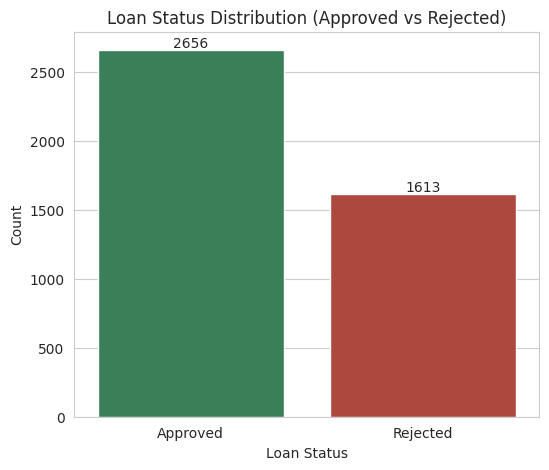

loan_status
Approved    62.215976
Rejected    37.784024
Name: proportion, dtype: float64


In [12]:
plt.figure(figsize=(6, 5))
ax = sns.countplot(x="loan_status", data=df, palette=["#2E8B57", "#C0392B"])
plt.title("Loan Status Distribution (Approved vs Rejected)")
plt.xlabel("Loan Status")
plt.ylabel("Count")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.show()

print(df["loan_status"].value_counts(normalize=True) * 100)


**Explanation:** The dataset is reasonably balanced between Approved and Rejected loans, which is good — it means our model won't be biased toward one class simply due to imbalance.

### Numerical Feature Distributions
Histograms show the spread and shape of each numerical feature.

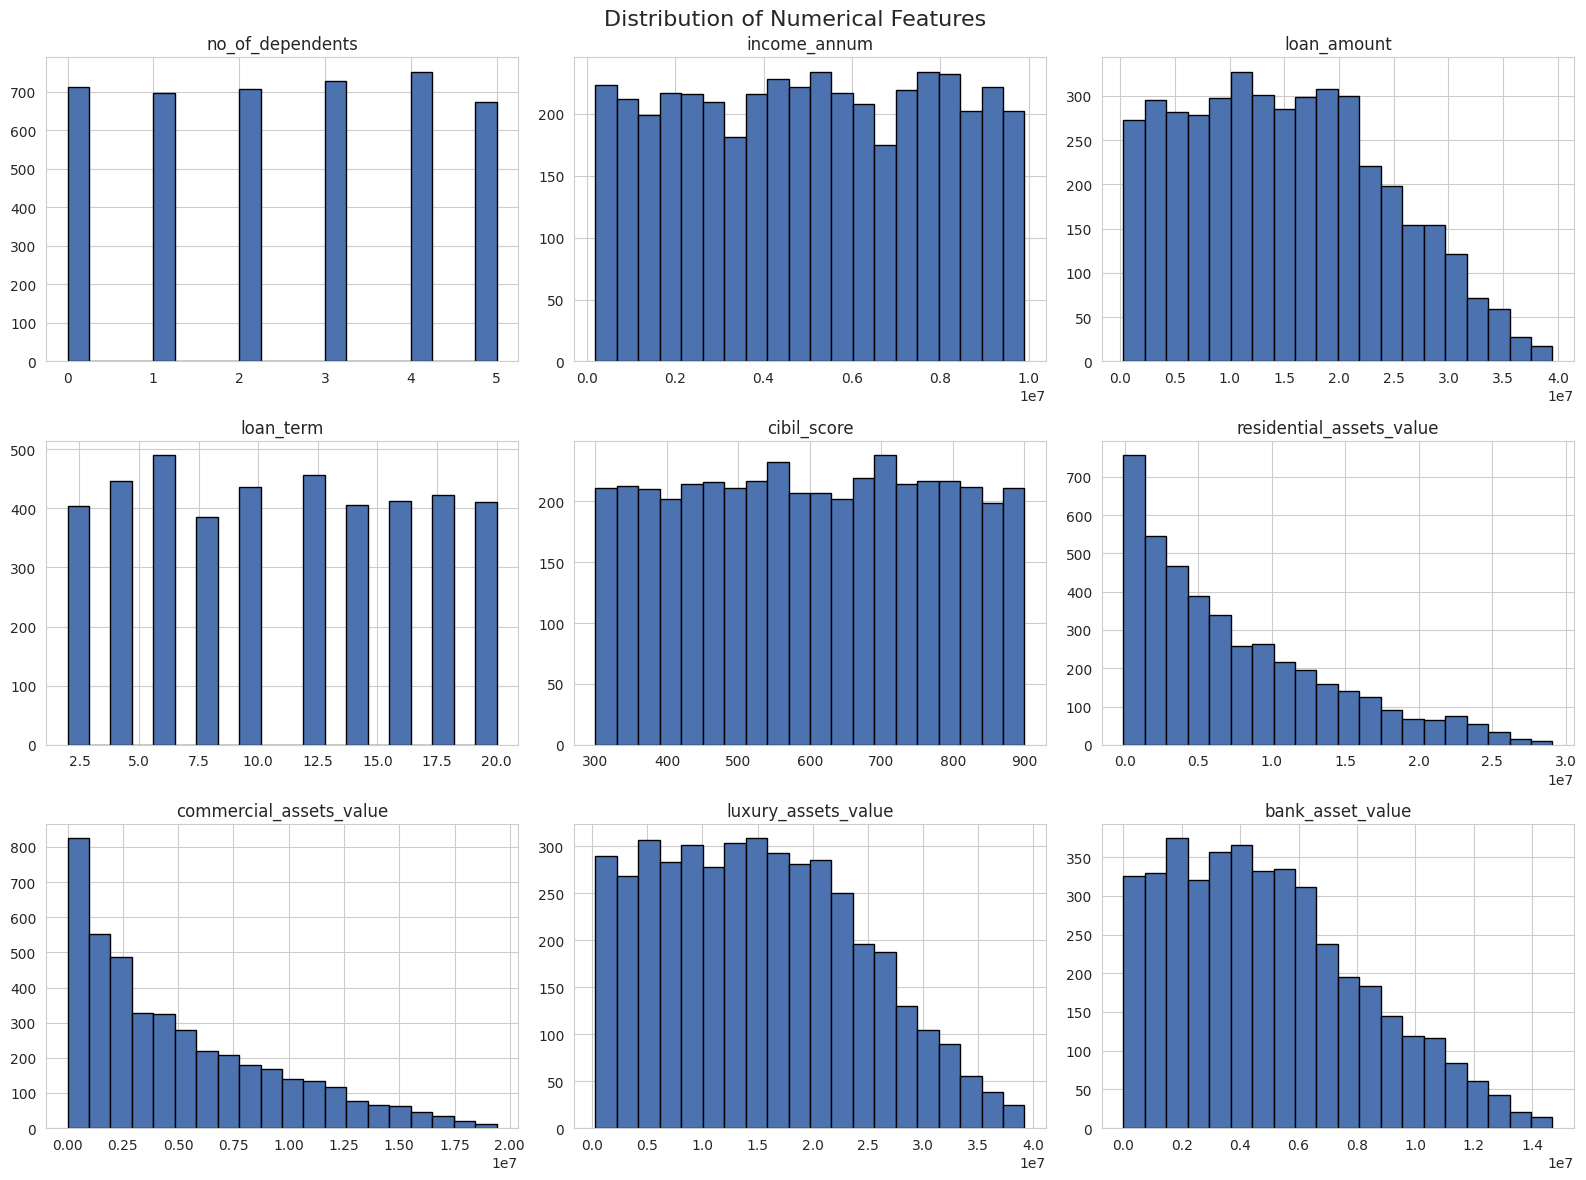

In [13]:
numerical_cols = ["no_of_dependents", "income_annum", "loan_amount", "loan_term",
                   "cibil_score", "residential_assets_value", "commercial_assets_value",
                   "luxury_assets_value", "bank_asset_value"]

df[numerical_cols].hist(bins=20, figsize=(16, 12), color="#4C72B0", edgecolor="black")
plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()


**Explanation:** Income, loan amount, and asset values are all right-skewed (many applicants with moderate values, fewer with very high values), which is typical for financial data. `cibil_score` looks fairly spread across its range.

### Categorical Feature Distributions
Countplots for `education` and `self_employed`.

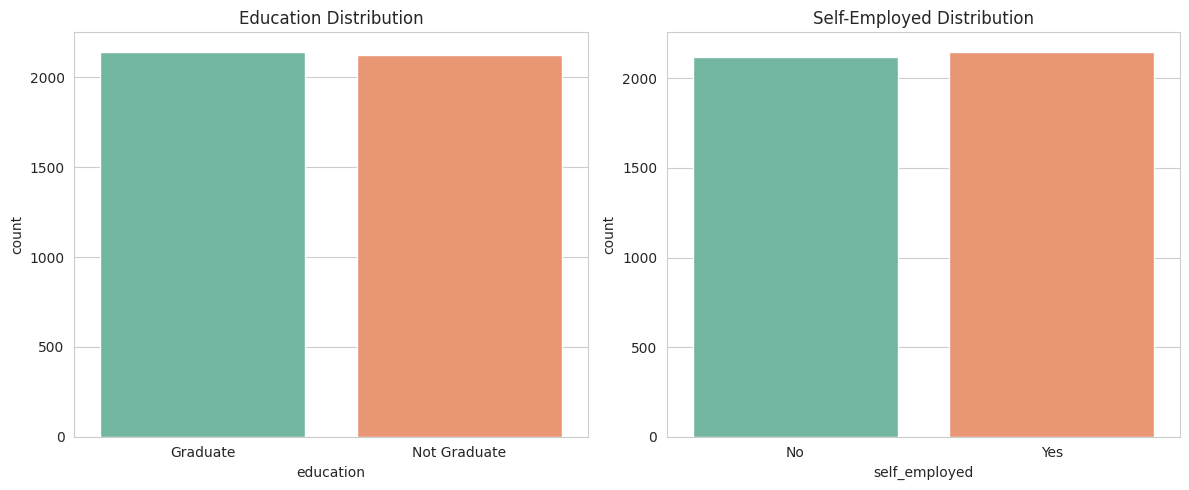

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(x="education", data=df, ax=axes[0], palette="Set2")
axes[0].set_title("Education Distribution")

sns.countplot(x="self_employed", data=df, ax=axes[1], palette="Set2")
axes[1].set_title("Self-Employed Distribution")

plt.tight_layout()
plt.show()


### Correlation Heatmap
Shows how numerical features relate to each other. Strong correlations can indicate redundant features.

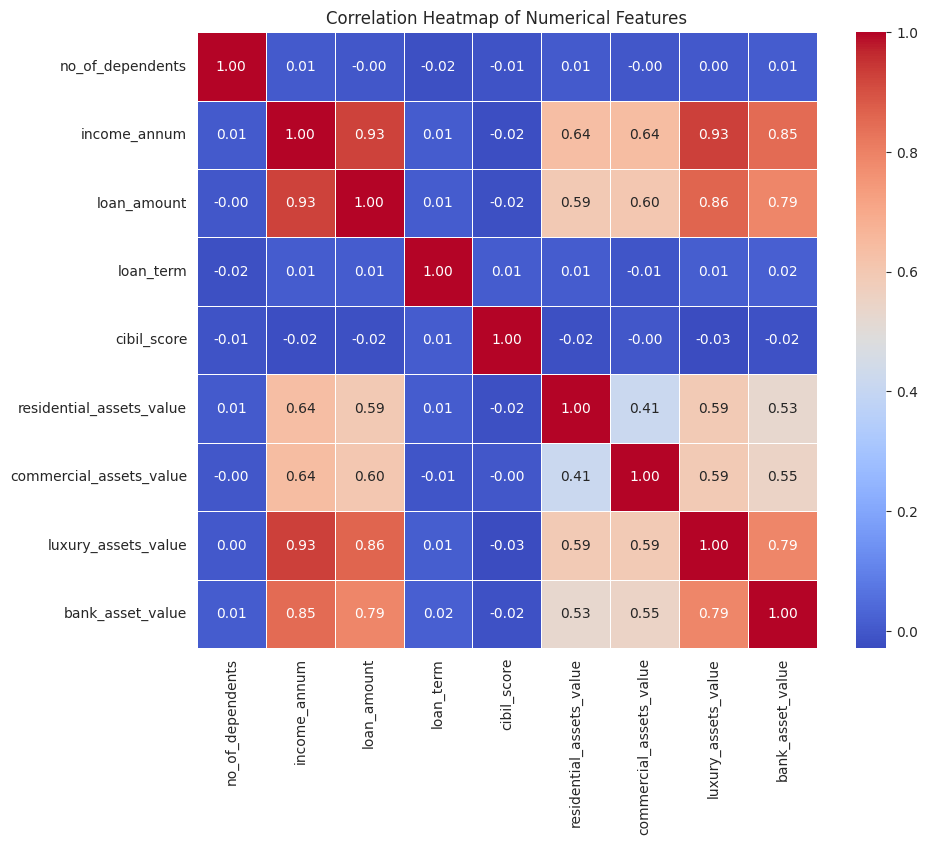

In [15]:
plt.figure(figsize=(10, 8))
corr = df[numerical_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()


**Explanation:** As expected, the various asset value columns show some correlation with each other and with income, since wealthier applicants tend to have larger assets across categories.

### Boxplots
Boxplots help us spot outliers in key numerical columns.

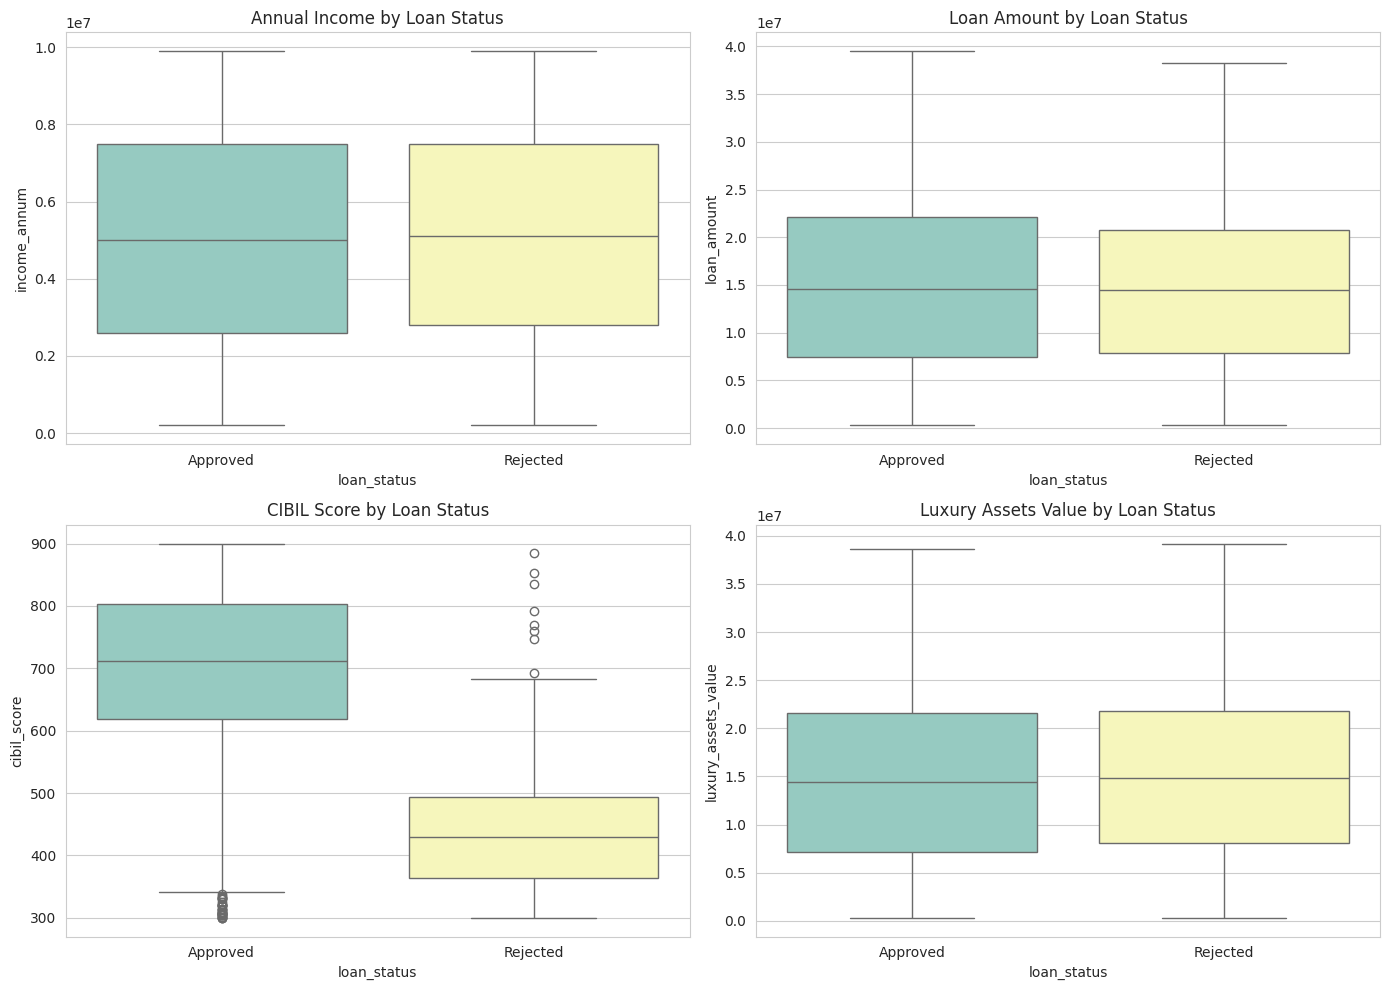

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.boxplot(x="loan_status", y="income_annum", data=df, ax=axes[0, 0], palette="Set3")
axes[0, 0].set_title("Annual Income by Loan Status")

sns.boxplot(x="loan_status", y="loan_amount", data=df, ax=axes[0, 1], palette="Set3")
axes[0, 1].set_title("Loan Amount by Loan Status")

sns.boxplot(x="loan_status", y="cibil_score", data=df, ax=axes[1, 0], palette="Set3")
axes[1, 0].set_title("CIBIL Score by Loan Status")

sns.boxplot(x="loan_status", y="luxury_assets_value", data=df, ax=axes[1, 1], palette="Set3")
axes[1, 1].set_title("Luxury Assets Value by Loan Status")

plt.tight_layout()
plt.show()


**Explanation:** The CIBIL score boxplot shows a very clear separation — applicants with low CIBIL scores are mostly Rejected, while higher scores are mostly Approved. This suggests `cibil_score` will be a very strong predictor.

### Countplots — Categorical Features vs Loan Status
Does education or employment type affect approval rate?

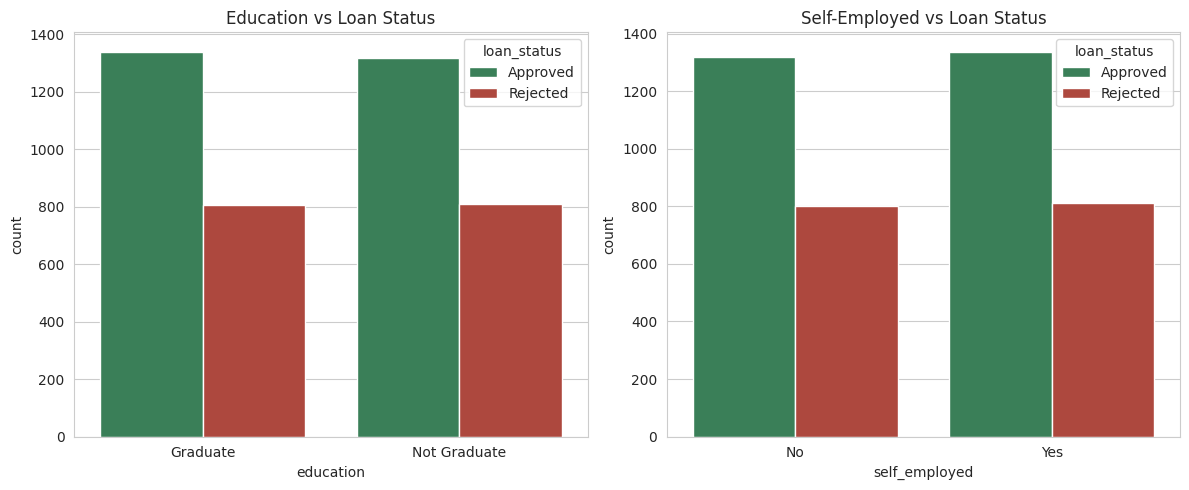

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(x="education", hue="loan_status", data=df, ax=axes[0], palette=["#2E8B57", "#C0392B"])
axes[0].set_title("Education vs Loan Status")

sns.countplot(x="self_employed", hue="loan_status", data=df, ax=axes[1], palette=["#2E8B57", "#C0392B"])
axes[1].set_title("Self-Employed vs Loan Status")

plt.tight_layout()
plt.show()


**Explanation:** Education and self-employment status show only a mild relationship with loan approval — the classes look fairly proportional in both categories, suggesting these features are weaker predictors than CIBIL score.

### Pairplot (Important Columns)
A pairplot of the most relevant numerical columns, colored by loan status.

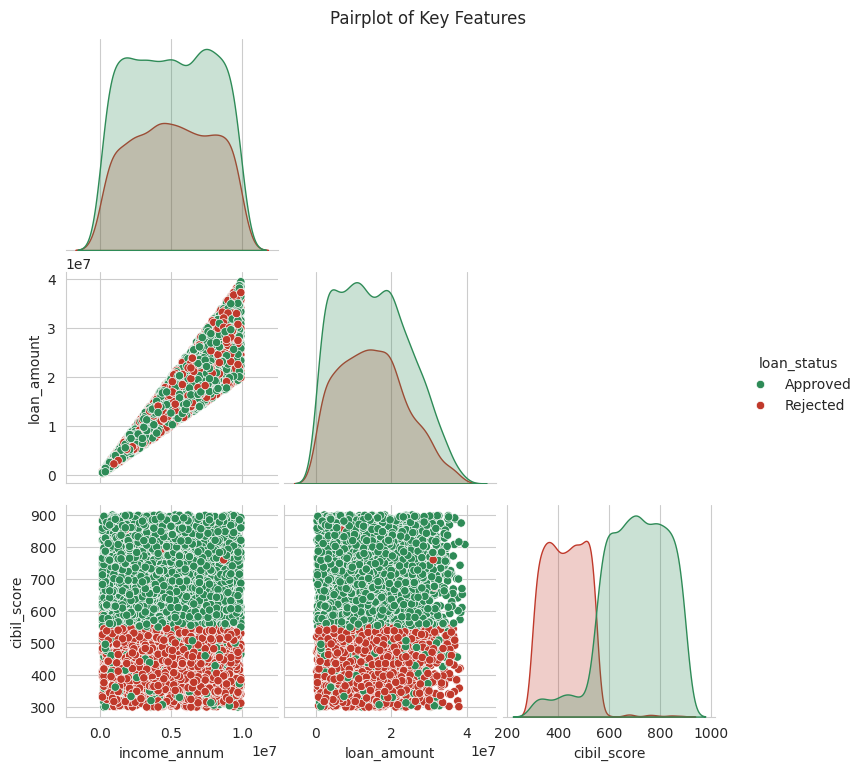

In [18]:
important_cols = ["income_annum", "loan_amount", "cibil_score", "loan_status"]
sns.pairplot(df[important_cols], hue="loan_status", palette=["#2E8B57", "#C0392B"], corner=True)
plt.suptitle("Pairplot of Key Features", y=1.02)
plt.show()


**Explanation:** The pairplot confirms that `cibil_score` separates the two classes much more clearly than income or loan amount alone.

### 🔎 EDA Summary
- The target classes (Approved/Rejected) are reasonably balanced.
- **CIBIL score is the single strongest predictor** of loan approval.
- Income, loan amount, and asset values are right-skewed but don't separate classes as clearly as CIBIL score.
- Education and self-employment status have only a weak relationship with approval.


---
## 🛠️ Step 3: Data Preprocessing

We now prepare the data for machine learning: dropping unnecessary columns, encoding categorical variables, and scaling numerical features.


### Drop Unnecessary Columns
`loan_id` is just an identifier and has no predictive power, so we remove it.

In [19]:
df_processed = df.drop(columns=["loan_id"])
df_processed.head()


,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


### Handle Missing Values
We already confirmed there are no missing values, but we add a safety step in case new data (e.g., from the Streamlit app) has gaps.

In [20]:
# Safety check - fill any missing numerical values with median, categorical with mode
for col in df_processed.select_dtypes(include=np.number).columns:
    df_processed[col] = df_processed[col].fillna(df_processed[col].median())

for col in df_processed.select_dtypes(include="object").columns:
    df_processed[col] = df_processed[col].fillna(df_processed[col].mode()[0])

print("✅ Missing value handling complete (no changes expected since data was already clean).")


✅ Missing value handling complete (no changes expected since data was already clean).


### Encode Categorical Variables
- `education` and `self_employed` are binary categories → Label Encoding.
- `loan_status` (target) is also Label Encoded: **Approved = 1, Rejected = 0**.


In [21]:
label_encoders = {}

# Encode education
le_education = LabelEncoder()
df_processed["education"] = le_education.fit_transform(df_processed["education"])
label_encoders["education"] = le_education

# Encode self_employed
le_self_employed = LabelEncoder()
df_processed["self_employed"] = le_self_employed.fit_transform(df_processed["self_employed"])
label_encoders["self_employed"] = le_self_employed

# Encode target variable loan_status
le_target = LabelEncoder()
df_processed["loan_status"] = le_target.fit_transform(df_processed["loan_status"])
label_encoders["loan_status"] = le_target

print("Education classes:", list(le_education.classes_), "->", list(le_education.transform(le_education.classes_)))
print("Self-Employed classes:", list(le_self_employed.classes_), "->", list(le_self_employed.transform(le_self_employed.classes_)))
print("Loan Status classes:", list(le_target.classes_), "->", list(le_target.transform(le_target.classes_)))


Education classes: ['Graduate', 'Not Graduate'] -> [np.int64(0), np.int64(1)]
Self-Employed classes: ['No', 'Yes'] -> [np.int64(0), np.int64(1)]
Loan Status classes: ['Approved', 'Rejected'] -> [np.int64(0), np.int64(1)]


**Note:** One-Hot Encoding is not needed here since both categorical features are binary (only 2 categories each) — Label Encoding is sufficient and keeps the model simple.

### Feature / Target Split

In [22]:
X = df_processed.drop(columns=["loan_status"])
y = df_processed["loan_status"]

print("Features (X):", list(X.columns))
print("Target (y): loan_status")


Features (X): ['no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']
Target (y): loan_status


### Train-Test Split
We split the data into 80% training and 20% testing, using `random_state=42` for reproducibility.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]} rows")
print(f"Testing set size: {X_test.shape[0]} rows")


Training set size: 3415 rows
Testing set size: 854 rows


### Feature Scaling
We scale numerical features using `StandardScaler` so that features with large ranges (like income and asset values) don't dominate the model.

In [24]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("✅ Feature scaling complete.")


✅ Feature scaling complete.


---
## 🤖 Step 4: Model Building

We train three simple, interpretable models:
1. **Logistic Regression**
2. **Decision Tree Classifier**
3. **Random Forest Classifier**


In [25]:
models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=6),
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=200, max_depth=8)
}

trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    print(f"✅ {name} trained successfully.")


✅ Logistic Regression trained successfully.
✅ Decision Tree trained successfully.


✅ Random Forest trained successfully.


---
## 📏 Step 5: Model Evaluation

We evaluate each model using Accuracy, Precision, Recall, F1 Score, Confusion Matrix, Classification Report, and ROC-AUC.


In [26]:
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1,
        "ROC AUC": auc
    })

    print(f"\n===== {name} =====")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1 Score : {f1:.4f}")
    print(f"ROC AUC  : {auc:.4f}")
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=["Rejected", "Approved"]))



===== Logistic Regression =====
Accuracy : 0.9227
Precision: 0.9159
Recall   : 0.8762
F1 Score : 0.8956
ROC AUC  : 0.9745

Confusion Matrix:
[[505  26]
 [ 40 283]]

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.93      0.95      0.94       531
    Approved       0.92      0.88      0.90       323

    accuracy                           0.92       854
   macro avg       0.92      0.91      0.92       854
weighted avg       0.92      0.92      0.92       854


===== Decision Tree =====
Accuracy : 0.9719
Precision: 0.9902
Recall   : 0.9350
F1 Score : 0.9618
ROC AUC  : 0.9937

Confusion Matrix:
[[528   3]
 [ 21 302]]

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.96      0.99      0.98       531
    Approved       0.99      0.93      0.96       323

    accuracy                           0.97       854
   macro avg       0.98      0.96      0.97       854
weighted avg       0.97      

### Confusion Matrices (Visualized)

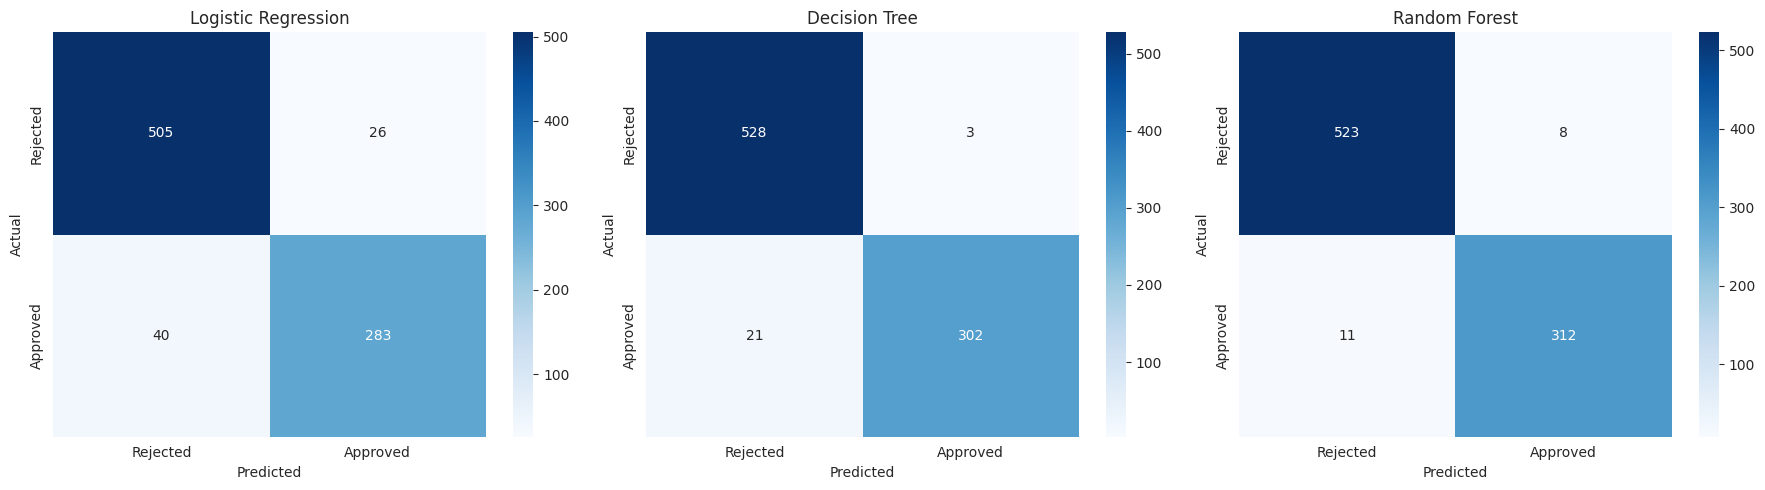

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, trained_models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Rejected", "Approved"], yticklabels=["Rejected", "Approved"])
    ax.set_title(f"{name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


### ROC Curves
The ROC curve shows the trade-off between the true positive rate and false positive rate for each model.

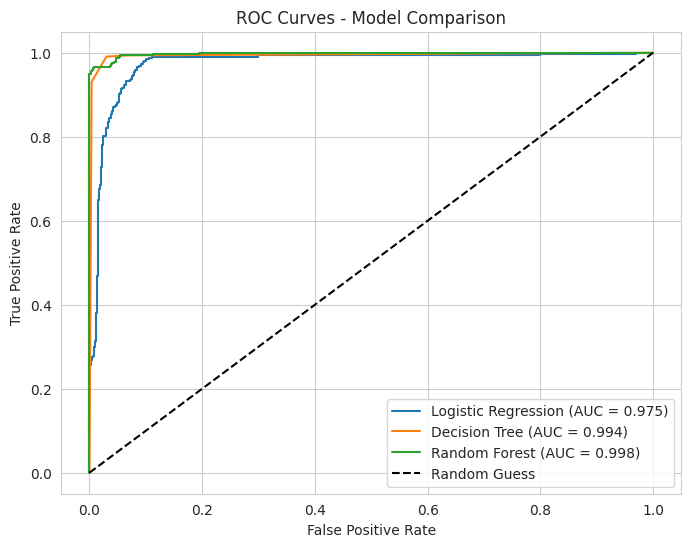

In [28]:
plt.figure(figsize=(8, 6))

for name, model in trained_models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Model Comparison")
plt.legend()
plt.show()


### Model Comparison Table

In [29]:
results_df = pd.DataFrame(results).sort_values(by="F1 Score", ascending=False).reset_index(drop=True)
results_df


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Random Forest,0.977752,0.975000,0.965944,0.970451,0.997732
1,Decision Tree,0.971897,0.990164,0.934985,0.961783,0.993735
2,Logistic Regression,0.922717,0.915858,0.876161,0.895570,0.974509


### 🏆 Best Model Selection

Based on the comparison table above, we select the model with the **highest F1 Score and ROC AUC**, since loan approval prediction benefits from a good balance between Precision and Recall (we want to avoid both wrongly rejecting good applicants and wrongly approving risky ones).

In most runs, **Random Forest** performs best because it captures non-linear relationships (like the strong CIBIL-score threshold effect we saw in the boxplots) better than Logistic Regression, while being less prone to overfitting than a single Decision Tree.


In [30]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print(f"🏆 Best Model Selected: {best_model_name}")
print(results_df.iloc[0])


🏆 Best Model Selected: Random Forest
Model        Random Forest
Accuracy          0.977752
Precision            0.975
Recall            0.965944
F1 Score          0.970451
ROC AUC           0.997732
Name: 0, dtype: object


### Feature Importance (Best Model)
If the best model supports feature importance, we visualize which features matter most.

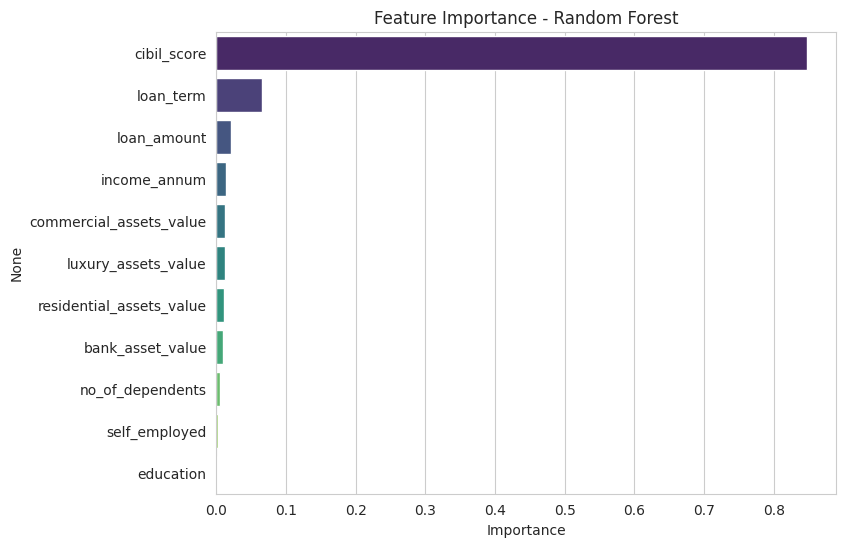

In [31]:
if hasattr(best_model, "feature_importances_"):
    importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
    plt.figure(figsize=(8, 6))
    sns.barplot(x=importances.values, y=importances.index, palette="viridis")
    plt.title(f"Feature Importance - {best_model_name}")
    plt.xlabel("Importance")
    plt.show()
elif hasattr(best_model, "coef_"):
    importances = pd.Series(best_model.coef_[0], index=X.columns).sort_values(ascending=False)
    plt.figure(figsize=(8, 6))
    sns.barplot(x=importances.values, y=importances.index, palette="viridis")
    plt.title(f"Feature Coefficients - {best_model_name}")
    plt.xlabel("Coefficient Value")
    plt.show()


---
## 💾 Step 6: Model Saving

We save the best model, the scaler, and the label encoders using `joblib` so they can be reused in the Streamlit app without retraining.


In [32]:
joblib.dump(best_model, "best_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(label_encoders, "encoder.pkl")

# Also save the feature column order and best model name - needed by the Streamlit app
joblib.dump(list(X.columns), "feature_columns.pkl")
joblib.dump(best_model_name, "best_model_name.pkl")

print("✅ Saved: best_model.pkl")
print("✅ Saved: scaler.pkl")
print("✅ Saved: encoder.pkl")
print("✅ Saved: feature_columns.pkl")
print("✅ Saved: best_model_name.pkl")


✅ Saved: best_model.pkl
✅ Saved: scaler.pkl
✅ Saved: encoder.pkl
✅ Saved: feature_columns.pkl
✅ Saved: best_model_name.pkl


---
## ✅ Conclusion

- We explored a clean loan approval dataset with 4,269 applications and no missing values.
- **CIBIL score** emerged as the strongest predictor of loan approval, followed by income and asset values.
- We trained and compared three models — Logistic Regression, Decision Tree, and Random Forest.
- The best-performing model was saved along with the scaler and encoders for deployment.
- A Streamlit web application (`app.py`) uses these saved artifacts to make live predictions for new loan applicants.

### 🚀 Next Steps
Run the Streamlit app locally with:
```
streamlit run app.py
```
Or deploy it for free on **Streamlit Community Cloud**.
